<a href="https://colab.research.google.com/github/QHIZER/BIS-LAB/blob/main/Cuckoo_Search_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


--- CUCKOO SEARCH RESULTS ---
Optimal Tilt Angle: 11.25 degrees
Maximum Solar Energy: 5132.97 kWh
Total Iterations: 10


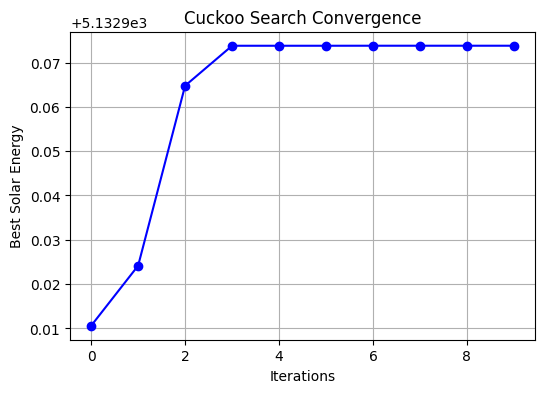

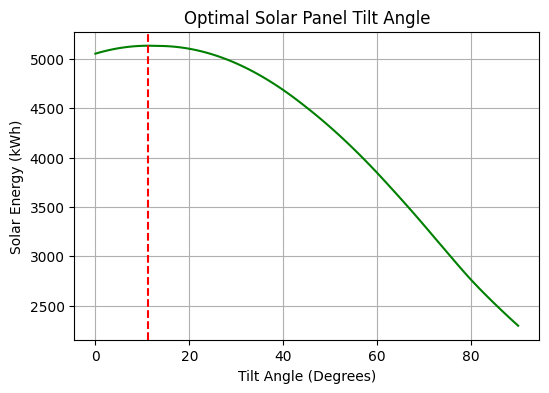

In [3]:

import numpy as np
import matplotlib.pyplot as plt
import math

# Cuckoo Search Parameters
n = 15
Pa = 0.25
MaxT = 10
beta = 1.5

# Solar Panel Parameters
latitude = 13.08
area = 10
efficiency = 0.20
DNI = 800
DHI = 100
albedo = 0.20

# Solar Energy Calculation
def solar_energy(tilt):

    lat = np.radians(latitude)
    tilt = np.radians(float(tilt))
    total = 0

    for day in range(1, 366, 5):

        dec = np.radians(
            23.45 * np.sin(
                np.radians(360 * (284 + day) / 365)
            )
        )

        for hour in range(6, 19):

            ha = np.radians(15 * (hour - 12))

            cz = (
                np.sin(lat) * np.sin(dec)
                + np.cos(lat) * np.cos(dec) * np.cos(ha)
            )

            if cz <= 0:
                continue

            ci = (
                np.sin(dec) * np.sin(lat - tilt)
                + np.cos(dec) * np.cos(ha) * np.cos(lat - tilt)
            )

            ghi = DNI * cz + DHI

            irradiance = (
                DNI * max(0, ci)
                + DHI * (1 + np.cos(tilt)) / 2
                + albedo * ghi * (1 - np.cos(tilt)) / 2
            )

            total += irradiance * area * efficiency / 1000

    return total * 365 / len(range(1, 366, 5))


# Fitness Function
def fitness(x):
    return -solar_energy(x[0])


# Levy Flight
def levy_flight(beta):

    sigma = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2)
        / (
            math.gamma((1 + beta) / 2)
            * beta * 2 ** ((beta - 1) / 2)
        )
    ) ** (1 / beta)

    u = np.random.normal(0, sigma)
    v = np.random.normal(0, 1)

    return u / abs(v) ** (1 / beta)


# Initialize Nests
nests = np.random.uniform(0, 90, (n, 1))

fitness_values = np.array([fitness(x) for x in nests])

best = nests[np.argmin(fitness_values)].copy()
best_fit = np.min(fitness_values)

history = []

# Cuckoo Search
for t in range(MaxT):

    for i in range(n):

        Xnew = nests[i] + levy_flight(beta) * np.random.randn(1)
        Xnew = np.clip(Xnew, 0, 90)

        j = np.random.randint(n)

        if fitness(Xnew) < fitness_values[j]:
            nests[j] = Xnew.copy()
            fitness_values[j] = fitness(Xnew)

    # Abandon worst nests
    count = max(1, int(Pa * n))
    worst = np.argsort(fitness_values)[-count:]

    for j in worst:
        nests[j] = np.random.uniform(0, 90, 1)
        fitness_values[j] = fitness(nests[j])

    # Update best
    idx = np.argmin(fitness_values)

    if fitness_values[idx] < best_fit:
        best_fit = fitness_values[idx]
        best = nests[idx].copy()

    history.append(-best_fit)


# Final Output
print("\n--- CUCKOO SEARCH RESULTS ---")
print("Optimal Tilt Angle:", round(best[0], 2), "degrees")
print("Maximum Solar Energy:", round(-best_fit, 2), "kWh")
print("Total Iterations:", MaxT)


# Convergence Graph
plt.figure(figsize=(6, 4))
plt.plot(history, 'b-o')
plt.title("Cuckoo Search Convergence")
plt.xlabel("Iterations")
plt.ylabel("Best Solar Energy")
plt.grid()
plt.show()


# Energy vs Tilt Angle
angles = np.linspace(0, 90, 100)
energy = [solar_energy(a) for a in angles]

plt.figure(figsize=(6, 4))
plt.plot(angles, energy, 'g')
plt.axvline(best[0], color='red', linestyle='--')
plt.xlabel("Tilt Angle (Degrees)")
plt.ylabel("Solar Energy (kWh)")
plt.title("Optimal Solar Panel Tilt Angle")
plt.grid()
plt.show()
